## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [6]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
print(token_count.most_common(30))

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598), ('online', 591), ('need', 587), ('wrote:', 585), ('see', 554), ('conference', 553), ('language', 550), ('want', 548), ('empty', 546), ('hourahead', 526), ('list', 523)]


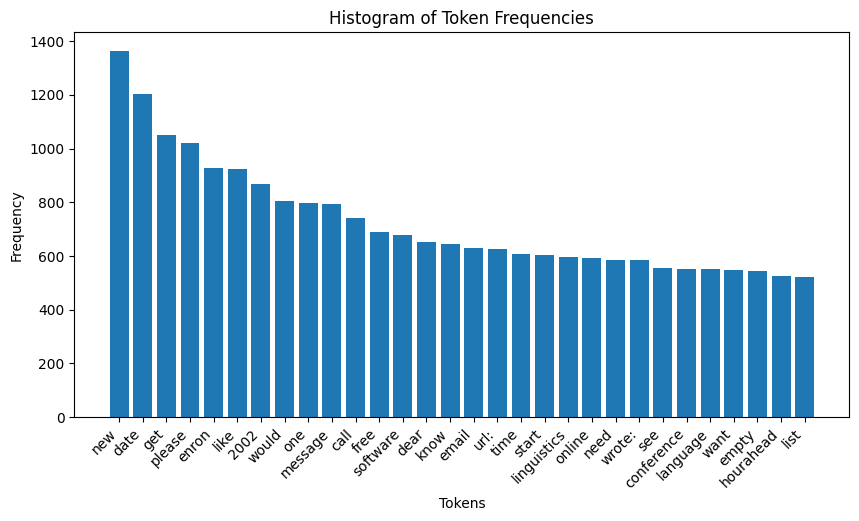

In [7]:
# histogram of ocurrences of tokens
import matplotlib.pyplot as plt
# didn't plot all bc it was messy
freq = token_freq[:30]

plt.figure(figsize=(10, 5))
plt.bar(range(len(freq)), [count for token, count in freq])

plt.xticks(range(len(freq)), [token[:15] for token, count in freq], rotation=45, ha='right' ,parse_math = False)
plt.xlabel('Tokens')
plt.ylabel('Frequency')
plt.title('Histogram of Token Frequencies')
plt.show()


Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

Q1. Tokens like new, date, and get appears the most with over 1000 occurences and then later tokens steady out to an average of about 500-600 occurences. It also seems that there are tokens related to communication like email, wrote, url, and message. There are also academic/professional categorical words like linguistics, software, and conference. 

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 80/20 train-test split
df = pd.read_parquet("data/Phishing_clean.parquet")

x = df.drop(columns=["Email Type"])
y = df["Email Type"]
train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Train set size: {len(train_x)}")
print(f"Test set size: {len(test_x)}")

# regression and r^2
regression_model = LinearRegression()
regression_model.fit(train_x, train_y)
predictions = regression_model.predict(train_x)
predictions_test = regression_model.predict(test_x)

print(f"Training set: {r2_score(train_y, predictions)}")
print(f"Test set: {r2_score(test_y, predictions_test)}")

# words with largest coefficients
coefficients = pd.DataFrame({'Word': x.columns, 'Coefficient': regression_model.coef_})
coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()
large_coeffinicients = coefficients.sort_values("Absolute Coefficient", ascending=False)

print(large_coeffinicients.head(10))


Train set size: 14907
Test set size: 3727
Training set: 0.7670143724934355
Test set: 0.665871843884793
                   Word  Coefficient  Absolute Coefficient
835        intervention    -1.259257              1.259257
740           localized     0.824350              0.824350
2362            thermal     0.747006              0.747006
851             crawler     0.696167              0.696167
1504  background-image:    -0.622909              0.622909
1406         helvetica,     0.598560              0.598560
906               aging     0.594956              0.594956
1839              form.     0.576886              0.576886
2242              gray;    -0.574480              0.574480
1552           a:active     0.574480              0.574480


/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: divide by zero encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: overflow encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:311: RuntimeWarning: invalid value encountered in matmul
  intercept_ = y_offset - X_offset @ coef_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9


2. After I performed a regression on y, I found that the R^2 on the test set was 0.6659 and the training was 0.7670. So about 76.7% of the variation in the training data and 66.6% of the variation in the training data. The lower test shows that the model performs better on the training data than on unseen emails. But the test shows that the model still shows a good amount of variation in the test set. 
3. The words with the largest coefficients are invention, localized, thermal, crawler, background-image. Postive coefficients means that a feature is associated with a higher prediction whereas negative is a lower prediction. Examples of a positive coefficient is the word localized (scam), and a negative one is intervention (not scam). These features have a strong influence on the model's predictions.

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value enc

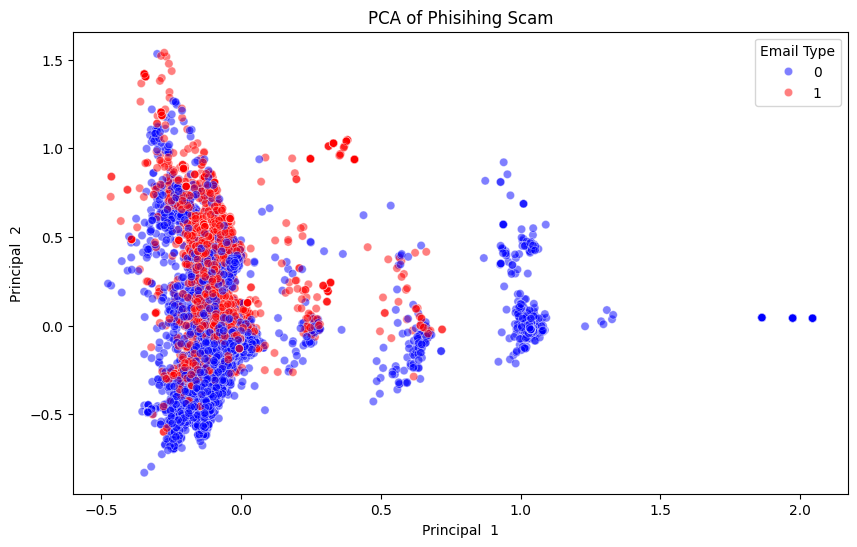

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt


X = df.drop(columns=["Email Type"])
y = df["Email Type"]
pca = PCA(n_components=2)

X_scaled = StandardScaler().fit_transform(X)
pca_x = pca.fit_transform(X)
pca_df = pd.DataFrame(pca_x, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values


plt.figure(figsize=(10, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', palette={0: 'blue', 1: 'red'}, alpha=0.5)
plt.title('PCA of Phisihing Scam')
plt.xlabel('Principal  1')
plt.ylabel('Principal  2')

plt.show()

Q3. The mixing of the phishing(red) and non-phishing(blue) points shows that those emails share very similar vocabulary in a standard one-hot encoded representation. This can show that scammers try to copy the standard business form of emails so that it's hard to seperate phishing versus non-phsishing emails. The isolated points on the right represent emails that conatain a set of rare tokens. 

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
train_x_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

n_components = min(2610, train_x_scaled.shape[1])
pca = PCA(n_components=n_components)
train_x_pca = pca.fit_transform(train_x_scaled)
x_test_pca = pca.transform(x_test_scaled)

model = LinearRegression()
model.fit(train_x_pca, y_train)
r2_train = model.score(train_x_pca, y_train)
r2_test = model.score(x_test_pca, y_test)
print(f"R^2 score on training set: {r2_train}")
print(f"R^2 score on test set: {r2_test}")

/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: divide by zero encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (1, -1)) @ self.components_.T
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/decomposition/_base.py:155: RuntimeWarning: overflow encountered in matmul
  X_transformed -= xp.reshape(self.mean_, (

R^2 score on training set: 0.7660928423789813
R^2 score on test set: 0.6684172405887809


/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/maleahcaboteja/Library/Python/3.9/lib/python/site-p

Q4. The linear regression model had an R^2 of 0.7670 on the training set and a 0.6659 on the test set. The linear regression model using the first 2,610 principal components achieved an R^2 of 0.7661 on the training set and a 0.6684 on the test set. The PCA is very similar to the original with a lower training R^2 but a slight high test R^2. The PCA could have maintained a comparable predictive performance with a small improvement in performance on the test set. 

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

I think that the advantage of using the principal components is the fact that they reduce the number of features while still preserving most of the important information in the data. PCA can reduce overlap between features, and therefore make the regression model more stable. The PCA model achieved almost identical performance to the original model, with a slightly higher R^2 test. This might suggest that PCA kept a predicitive performance and while it simplified the data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maleah Caboteja

**Date:** 10/20/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.
# above answers ^^

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 4c9ea7d84af10217ed183899927d616d255f3bea
- **AI tool and model used:** chatgpt

### *Prompts used

1. Is there anything wrong with my code, if so what can I do
2. How else can I improve my code?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Avoid scaling the data twice
2. Use a scikit-learn pipeline
3. Check for overfitting

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | reject | 	I think my code still works fine, I think all of these are just for clear reading and safety purposes |
| 2 | reject | 	I think my code still works fine, I think all of these are just for clear reading and safety purposes |
| 3 | reject | 	I think my code still works fine, I think all of these are just for clear reading and safety purposes |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.
# histogram of ocurrences of tokens
import matplotlib.pyplot as plt
# didn't plot all bc it was messy
freq = token_freq[:30]

plt.figure(figsize=(10, 5))
plt.bar(range(len(freq)), [count for token, count in freq])

plt.xticks(range(len(freq)), [token[:15] for token, count in freq], rotation=45, ha='right' ,parse_math = False)
plt.xlabel('Tokens')
plt.ylabel('Frequency')
plt.title('Histogram of Token Frequencies')
plt.show()


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 80/20 train-test split
df = pd.read_parquet("data/Phishing_clean.parquet")

x = df.drop(columns=["Email Type"])
y = df["Email Type"]
train_x, test_x, train_y, test_y = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Train set size: {len(train_x)}")
print(f"Test set size: {len(test_x)}")

# regression and r^2
regression_model = LinearRegression()
regression_model.fit(train_x, train_y)
predictions = regression_model.predict(train_x)
predictions_test = regression_model.predict(test_x)

print(f"Training set: {r2_score(train_y, predictions)}")
print(f"Test set: {r2_score(test_y, predictions_test)}")

# words with largest coefficients
coefficients = pd.DataFrame({'Word': x.columns, 'Coefficient': regression_model.coef_})
coefficients["Absolute Coefficient"] = coefficients["Coefficient"].abs()
large_coeffinicients = coefficients.sort_values("Absolute Coefficient", ascending=False)

print(large_coeffinicients.head(10))


In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt


X = df.drop(columns=["Email Type"])
y = df["Email Type"]
pca = PCA(n_components=2)

X_scaled = StandardScaler().fit_transform(X)
pca_x = pca.fit_transform(X)
pca_df = pd.DataFrame(pca_x, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values


plt.figure(figsize=(10, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', palette={0: 'blue', 1: 'red'}, alpha=0.5)
plt.title('PCA of Phisihing Scam')
plt.xlabel('Principal  1')
plt.ylabel('Principal  2')

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
train_x_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

n_components = min(2610, train_x_scaled.shape[1])
pca = PCA(n_components=n_components)
train_x_pca = pca.fit_transform(train_x_scaled)
x_test_pca = pca.transform(x_test_scaled)

model = LinearRegression()
model.fit(train_x_pca, y_train)
r2_train = model.score(train_x_pca, y_train)
r2_test = model.score(x_test_pca, y_test)
print(f"R^2 score on training set: {r2_train}")
print(f"R^2 score on test set: {r2_test}")

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

I think because I have resources to the course material it makes the assignment easier to do without AI and I think AI is very good at providing suggestions on how to make the code more concise and understandable from the eyes of other people reaading your code. I decided not to make any improvements because I think the way I wrote my code has a good layout that helps people understand the flow of my thought process and intention. My final solution is what I already had and I don't think I have any other concerns about the process or project. I will say, I think that math is a lot easier to understand for me when it's in code instead of actually hand-writing the math, so I think that built-in functions that do math and visualize it is what makes this easier and more fun to do. 